# Exploratory Data Analysis (EDA)

## Objective

The objective of this notebook is to explore the cleaned NYC Taxi Trips dataset and identify patterns, trends, and business insights.

Key Questions:

1. What are the busiest pickup hours?
2. Which weekdays generate the most trips?
3. How is trip duration distributed?
4. How does passenger count impact trip duration?
5. Are there peak demand periods?
6. What insights can support transportation optimization?

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv(
    '../data/processed/NYC_cleaned.csv'
    )

df.head()


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_year,pickup_month,pickup_day,pickup_hour,pickup_weekday
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455,2016,3,14,17,Monday
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663,2016,6,12,0,Sunday
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,2016,1,19,11,Tuesday
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429,2016,4,6,19,Wednesday
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435,2016,3,26,13,Saturday


In [3]:
hourly_trips = (
    df['pickup_hour']
    .value_counts()
    .sort_index()
)

print(
    hourly_trips
)

pickup_hour
0     52775
1     38220
2     27661
3     20637
4     15524
5     14766
6     32933
7     55211
8     66662
9     67252
10    65032
11    68024
12    71367
13    70974
14    73696
15    71219
16    63750
17    75909
18    90017
19    89752
20    83532
21    83604
22    79933
23    69305
Name: count, dtype: int64


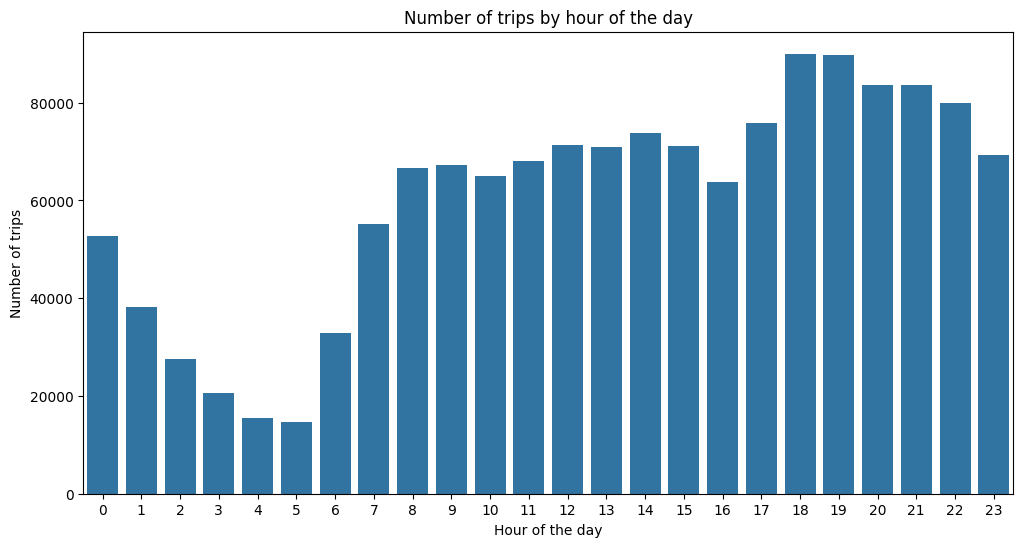

In [4]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=hourly_trips.index,
    y=hourly_trips.values
)

plt.title('Number of trips by hour of the day')
plt.xlabel('Hour of the day')
plt.ylabel('Number of trips')

plt.show()

In [17]:
plt.savefig(
    "../assets/Number of Trips by Hour.png"
)

<Figure size 640x480 with 0 Axes>

### Business Insight

Trip demand varies across weekdays.

Friday records the highest number of trips, followed closely by Saturday and Thursday.

Monday shows the lowest demand.

The results suggest that transportation activity increases toward the end of the week, likely due to social and leisure activities.

In [6]:
weedly_trips = (
    df['pickup_weekday']
    .value_counts()
)



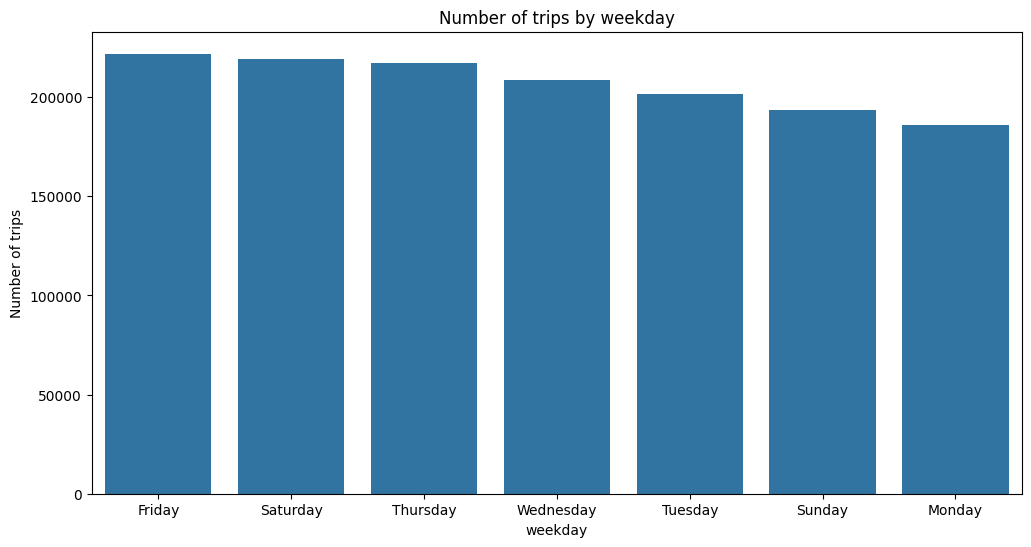

In [7]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=weedly_trips.index,
    y=weedly_trips.values
)

plt.title('Number of trips by weekday')
plt.xlabel('weekday')
plt.ylabel('Number of trips')

plt.show()

In [18]:
plt.savefig(
    "../assets/Weekday Demand.png"
)

<Figure size 640x480 with 0 Axes>

### Business Insight

Taxi demand is highly influenced by the time of day.

The number of trips decreases significantly during the early morning hours (2 AM to 6 AM).

Demand starts increasing around 7 AM and reaches its highest level between 6 PM and 9 PM.

This pattern is consistent with commuting and evening travel activities across New York City.

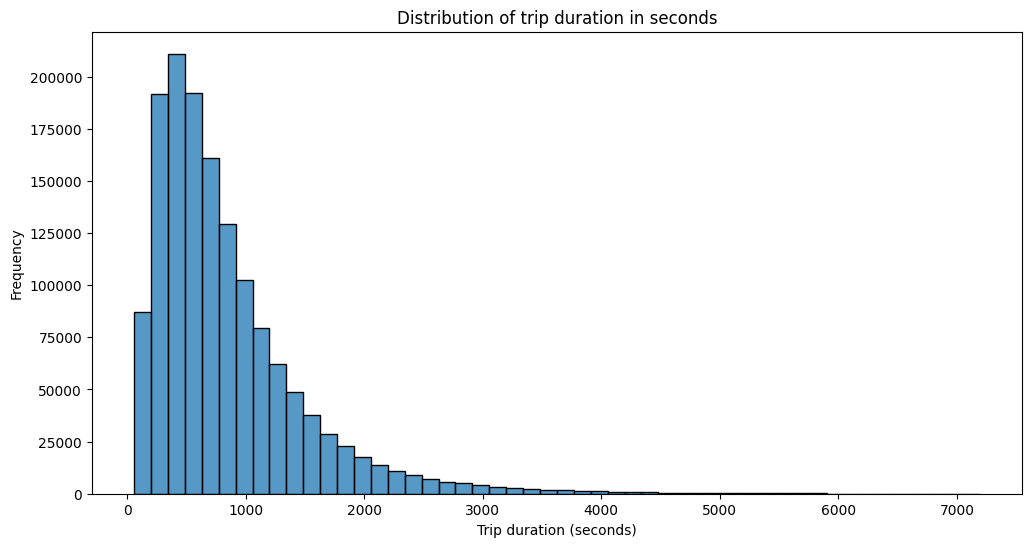

In [8]:
plt.figure(figsize=(12, 6))

sns.histplot(
    df['trip_duration'],
    bins=50

)

plt.title('Distribution of trip duration in seconds')
plt.xlabel('Trip duration (seconds)')
plt.ylabel('Frequency')

plt.show()

### Business Insight

Trip duration is right-skewed.

Most trips are relatively short, with a high concentration of rides under 1,500 seconds.

Long-duration trips exist but become increasingly rare as trip duration increases.

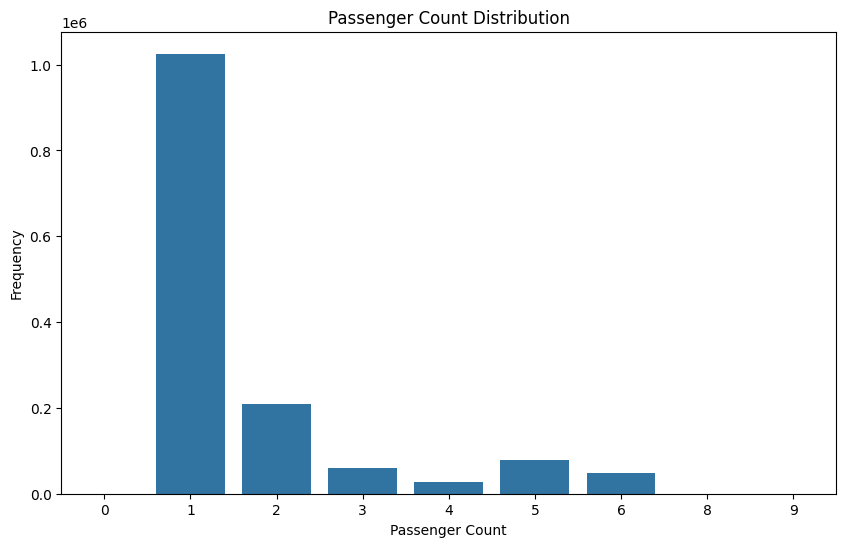

In [9]:
plt.figure(figsize=(10,6))

sns.countplot(
    x=df["passenger_count"]
)

plt.title(
    "Passenger Count Distribution")

plt.xlabel("Passenger Count")
plt.ylabel("Frequency")
plt.show()

### Business Insight

The majority of taxi trips involve only one passenger.

Passenger counts greater than 4 are relatively uncommon, indicating that most taxi demand comes from individual travelers rather than groups.

This suggests that transportation services should primarily optimize for single-passenger journeys.

In [10]:
avg_duration = (
    df.groupby("pickup_hour")
    ["trip_duration"]
    .mean()
)

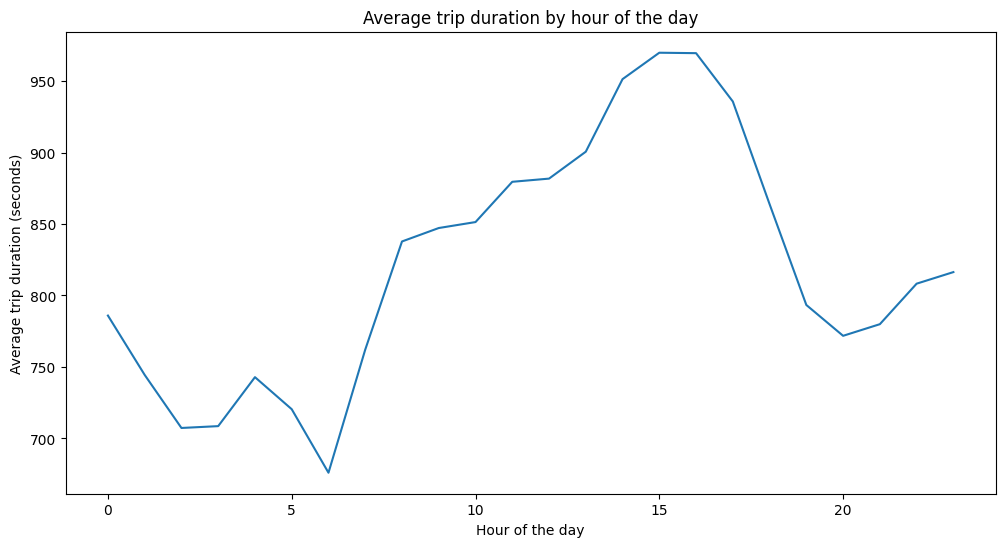

In [11]:
plt.figure(figsize=(12,6))

sns.lineplot(
    x=avg_duration.index,
    y=avg_duration.values
)

plt.title('Average trip duration by hour of the day')

plt.xlabel('Hour of the day')

plt.ylabel('Average trip duration (seconds)')

plt.show()

### Business Insight

Average trip duration varies throughout the day.

Trip durations increase significantly during the afternoon, reaching their highest levels around 3 PM to 4 PM.

This pattern may be associated with increased traffic congestion during peak travel periods.

In [12]:
numerical_features = [
    "vendor_id",
    "passenger_count",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "pickup_hour",
    "pickup_month",
    "trip_duration"
]

In [13]:
correlation_matrix = (
    df[numerical_features]
    .corr()
    )

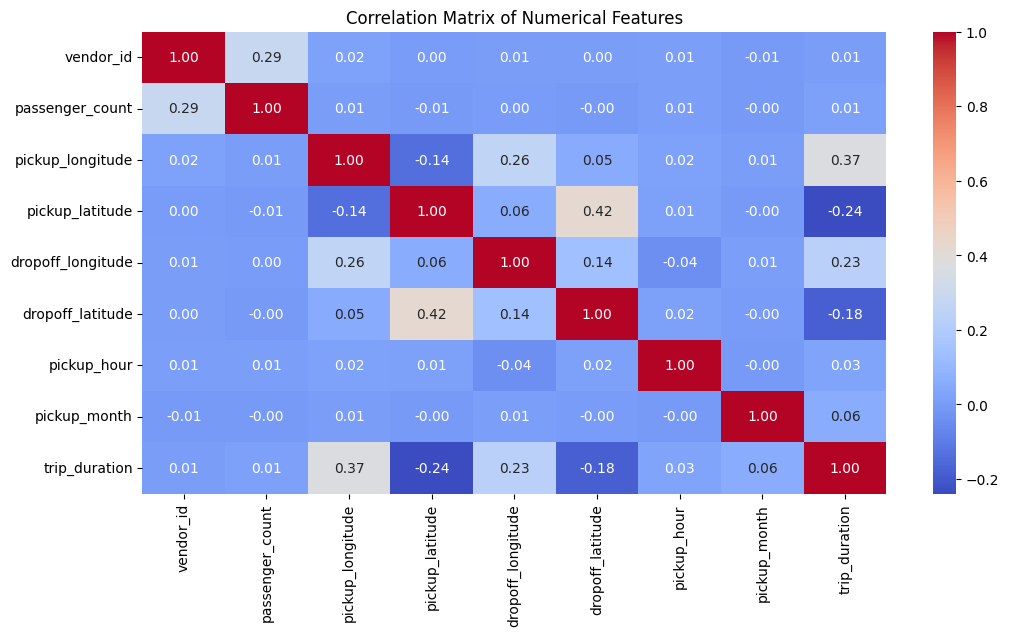

In [14]:
plt.figure(figsize=(12,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Features')

plt.show()

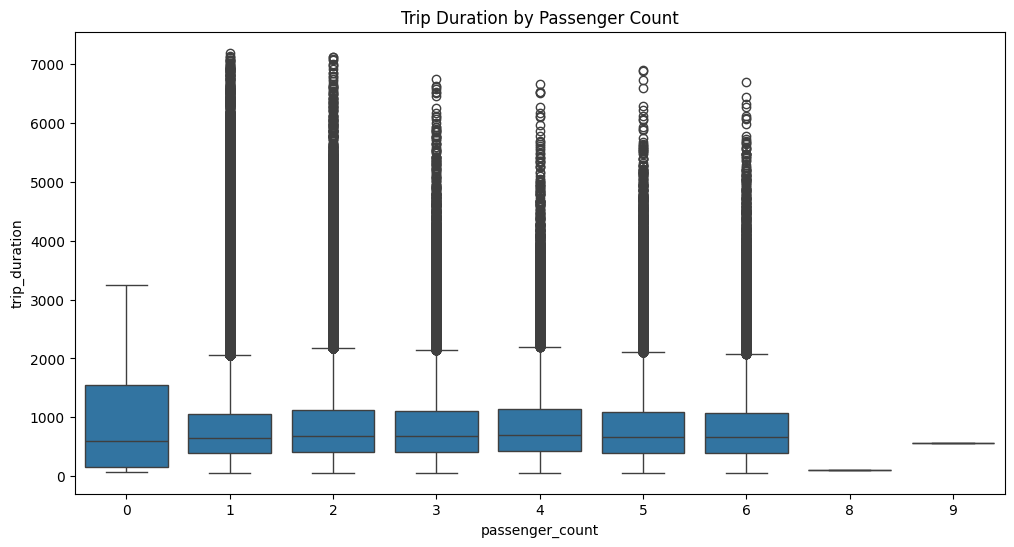

In [15]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    x='passenger_count',
    y='trip_duration',
    data=df
)

plt.title('Trip Duration by Passenger Count')

plt.show()

In [16]:
top_hours = (
    df["pickup_hour"]
    .value_counts()
    .head(10)
    .rename_axis("Hour")
    .reset_index(name="Trips")
)

top_hours.insert(0, "Rank", range(1, len(top_hours) + 1))

print(top_hours)

   Rank  Hour  Trips
0     1    18  90017
1     2    19  89752
2     3    21  83604
3     4    20  83532
4     5    22  79933
5     6    17  75909
6     7    14  73696
7     8    12  71367
8     9    15  71219
9    10    13  70974


The highest taxi demand occurs between 5 PM and 10 PM.

Peak demand is observed at 6 PM, with more than 90,000 trips recorded.

This pattern indicates strong evening commuting and social activity demand.